**Решение задачи
о многоруком бандите**

In [1]:
import torch

class BanditEnv():
#Окружающая среда с многоруким бандитом
#payout_list Список вероятностей выигрышей отдельных рычагов
#reward_list Список величин выигрышей

     def __init__(self, payout_list, reward_list):
         self.payout_list = payout_list
         self.reward_list = reward_list

     def step(self, action):
         if torch.rand(1).item() < self.payout_list[action]:
             return self.reward_list[action]
         return 0

In [2]:
# задача о  многоруком бандите, применяя случайную стратегию
#Определим вероятности и величины выигрыша для трехрукого бандита и создадим экземпляр окружающей среды. Например, выбор рычага 0 приносит вознаграждение 4 с вероятностью 10 %
bandit_payout = [0.1, 0.15, 0.3]
bandit_reward = [4, 3, 1]
bandit_env = BanditEnv(bandit_payout, bandit_reward)

In [3]:
#Зададим количество эпизодов и определим списки для хранения следующих данных: полное вознаграждение, полученное при выборе каждого рычага, сколько раз выбирался каждый рычаг и среднее вознаграждение для каждого рычага.
n_episode = 100000
n_action = len(bandit_payout)
action_count = [0 for _ in range(n_action)]
action_total_reward = [0 for _ in range(n_action)]
action_avg_reward = [[] for action in range(n_action)]

In [4]:
# Определим стратегию, которая выбирает рычаг случайным образом
def random_policy():
     action = torch.multinomial(torch.ones(n_action), 1).item()
     return action

In [5]:
# Прогоним 100 000 эпизодов. После каждого эпизода будем обновлять статистику рычагов
for episode in range(n_episode):
     action = random_policy()
     reward = bandit_env.step(action)
     action_count[action] += 1
     action_total_reward[action] += reward
     for a in range(n_action):
         if action_count[a]:
             action_avg_reward[a].append(
                    action_total_reward[a] / action_count[a])
         else:
             action_avg_reward[a].append(0)


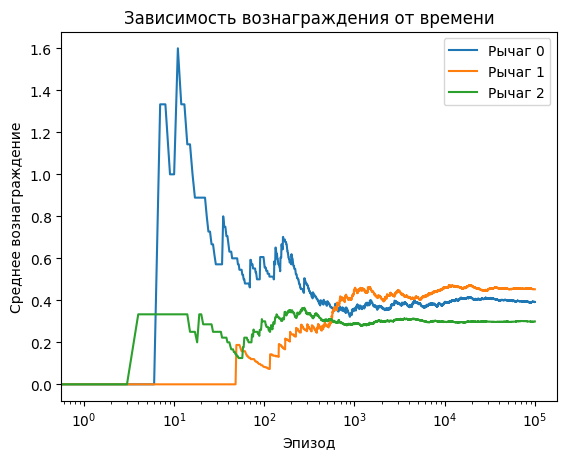

In [6]:
# По завершении построим график зависимости среднего вознаграждения от времени
import matplotlib.pyplot as plt

for action in range(n_action):
  plt.plot(action_avg_reward[action])
plt.legend(['Рычаг {}'.format(action) for action in range(n_action)])
plt.title('Зависимость вознаграждения от времени')
plt.xscale('log')
plt.xlabel('Эпизод')
plt.ylabel('Среднее вознаграждение')
plt.show()

In [7]:
print(sum(action_total_reward) / n_episode)

0.38149


**Решение задачи о многоруком бандите С Помощью ε-жадной Стратегии**


Основная идея - выбираем ручку с наибольшим средним

Выбираем случайную ручку с некоторой вероятностью  ϵ

ε-жад ная стратегия решения задачи о многоруком бандите большую часть времени использует лучшее из найденных действий, но иногда исследует другие действия. Точнее, вероятность исследования равна ε, а вероятность использования – 1 – ε, где ε – число от 0 до 1.


In [8]:
# 1. Определим вероятности и величины выигрыша для трехрукого бандита и создадим экземпляр окружающей среды
bandit_payout = [0.1, 0.15, 0.3]
bandit_reward = [4, 3, 1]
bandit_env = BanditEnv(bandit_payout, bandit_reward)

2. Зададим количество эпизодов и определим списки для хранения следующих данных: полное вознаграждение, полученное при выборе каждого рычага, сколько раз выбирался каждый рычаг и среднее вознаграждение
для каждого рычага.

In [9]:
n_episode = 100000
n_action = len(bandit_payout)
action_count = [0 for _ in range(n_action)]
action_total_reward = [0 for _ in range(n_action)]
action_avg_reward = [[] for action in range(n_action)]

3. Определим функцию ε-жад ной стратегии, зададим значение ε и создадим экземпляр стратегии

In [10]:
def gen_epsilon_greedy_policy(n_action, epsilon):
     def policy_function(Q):
         probs = torch.ones(n_action) * epsilon / n_action
         best_action = torch.argmax(Q).item()
         probs[best_action] += 1.0 - epsilon
         action = torch.multinomial(probs, 1).item()
         return action
     return policy_function
epsilon = 0.2
epsilon_greedy_policy = gen_epsilon_greedy_policy(n_action, epsilon)

4. Инициализируем Q-функцию, которая будет возвращать среднее вознаграждение для каждого рычага

In [11]:
Q = torch.zeros(n_action)

In [12]:
for episode in range(n_episode):
     action = epsilon_greedy_policy(Q)
     reward = bandit_env.step(action)
     action_count[action] += 1
     action_total_reward[action] += reward
     Q[action] = action_total_reward[action] / action_count[action]
     for a in range(n_action):
         if action_count[a]:
             action_avg_reward[a].append(
                        action_total_reward[a] / action_count[a])
         else:
             action_avg_reward[a].append(0)

5. По завершении построим график зависимости среднего вознаграждения от времени:


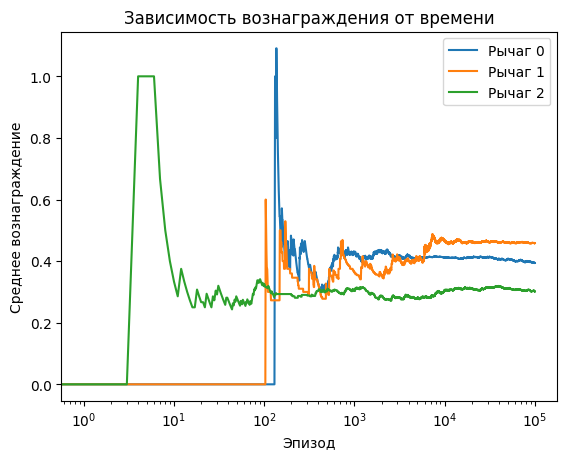

In [13]:
import matplotlib.pyplot as plt
for action in range(n_action):
     plt.plot(action_avg_reward[action])
plt.legend(['Рычаг {}'.format(action) for action in range(n_action)])
plt.title('Зависимость вознаграждения от времени')
plt.xscale('log')
plt.xlabel('Эпизод')
plt.ylabel('Среднее вознаграждение')
plt.show()


Вывод: Рычаг 1 дает наибольшее среднее вознаграждение. Среднее вознаграждение
стабилизируется после примерно 1000 эпизодов.

**Решение задачи о многоруком бандите
С Помощью SOFtmAx-исследования**

1. Определим вероятности и величины выигрыша для трехрукого бандита
и создадим экземпляр окружающей среды:


In [15]:
bandit_payout = [0.1, 0.15, 0.3]
bandit_reward = [4, 3, 1]
bandit_env = BanditEnv(bandit_payout, bandit_reward)

2. Зададим количество эпизодов и определим списки для хранения следующих данных: полное вознаграждение, полученное при выборе каждого
рычага, сколько раз выбирался каждый рычаг и среднее вознаграждение
для каждого рычага

In [16]:
n_episode = 100000
n_action = len(bandit_payout)
action_count = [0 for _ in range(n_action)]
action_total_reward = [0 for _ in range(n_action)]
action_avg_reward = [[] for action in range(n_action)]

3. Определим функцию softmax-исследования, зададим значение τ и создадим экземпляр стратегии:

In [17]:
def gen_softmax_exploration_policy(tau):
     def policy_function(Q):
         probs = torch.exp(Q / tau)
         probs = probs / torch.sum(probs)
         action = torch.multinomial(probs, 1).item()
         return action
     return policy_function
tau = 0.1
softmax_exploration_policy = gen_softmax_exploration_policy(tau)

5. Инициализируем Q-функцию, которая будет возвращать среднее вознаграждение для каждого рычага:


In [18]:
Q = torch.zeros(n_action)

6. Прогоним 100  000 эпизодов. После каждого эпизода будем обновлять
статистику рычагов:

In [19]:
for episode in range(n_episode):
     action = softmax_exploration_policy(Q)
     reward = bandit_env.step(action)
     action_count[action] += 1
     action_total_reward[action] += reward
     Q[action] = action_total_reward[action] / action_count[action]
     for a in range(n_action):
         if action_count[a]:
             action_avg_reward[a].append(
                            action_total_reward[a] / action_count[a])
         else:
             action_avg_reward[a].append(0)

7. По завершении построим график зависимости среднего вознаграждения от времени:

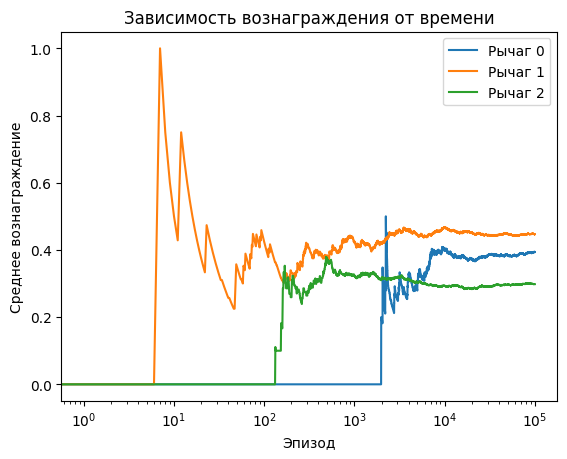

In [20]:
import matplotlib.pyplot as plt
for action in range(n_action):
     plt.plot(action_avg_reward[action])
plt.legend(['Рычаг {}'.format(action) for action in range(n_action)])
plt.title('Зависимость вознаграждения от времени')
plt.xscale('log')
plt.xlabel('Эпизод')
plt.ylabel('Среднее вознаграждение')
plt.show()

Вывод: Рычаг 1 дает наибольшее среднее вознаграждение. Среднее вознаграждение
стабилизируется после примерно 800 эпизодов

**Решение задачи о рекламе в интернете
С Помощью алгоритма многорукого бандита**

1. Определим вероятности и величины выигрыша для трехрукого бандита
и создадим экземпляр окружающей среды:


In [22]:
bandit_payout = [0.01, 0.015, 0.03]
bandit_reward = [1, 1, 1]
bandit_env = BanditEnv(bandit_payout, bandit_reward)

Здесь CTR для объявления 0 равен 1 %, для объявления 1 – 1.5 %, а для
объявления 2 – 3 %

Зададим количество эпизодов и определим списки для хранения следующих данных: полное вознаграждение, полученное при выборе каждого
рычага, сколько раз выбирался каждый рычаг и среднее вознаграждение
для каждого рычага.

In [23]:
n_episode = 100000
n_action = len(bandit_payout)
action_count = torch.tensor([0. for _ in range(n_action)])
action_total_reward = [0 for _ in range(n_action)]
action_avg_reward = [[] for action in range(n_action)]

2. Определим функцию стратегии UCB, которая вычисляет лучший рычаг
по формуле верхней доверительной границы:

In [24]:
def upper_confidence_bound(Q, action_count, t):
     ucb = torch.sqrt((2 * torch.log(
                    torch.tensor(float(t)))) / action_count) + Q
     return torch.argmax(ucb)

3. Инициализируем Q-функцию, которая будет возвращать среднее вознаграждение для каждого рычага

In [25]:
Q = torch.empty(n_action)

4. Прогоним 100 000 эпизодов со стратегией UCB. После каждого эпизода будем обновлять статистику рычагов:

In [26]:
for episode in range(n_episode):
     action = upper_confidence_bound(Q, action_count, episode)
     reward = bandit_env.step(action)
     action_count[action] += 1
     action_total_reward[action] += reward
     Q[action] = action_total_reward[action] / action_count[action]
     for a in range(n_action):
         if action_count[a]:
             action_avg_reward[a].append(
                    action_total_reward[a] / action_count[a])
         else:
             action_avg_reward[a].append(0)

5. По завершении построим график зависимости среднего вознаграждения от времени:

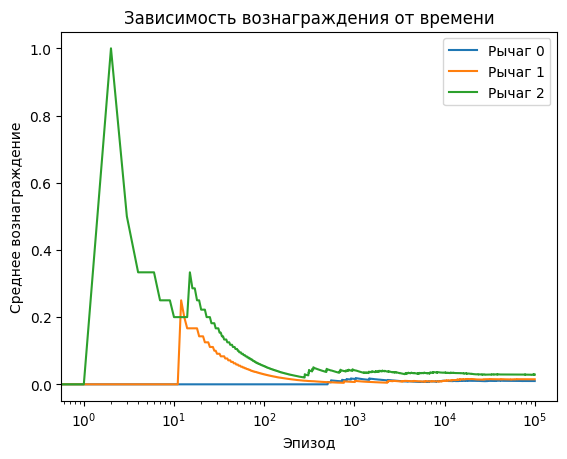

In [27]:
import matplotlib.pyplot as plt
for action in range(n_action):
     plt.plot(action_avg_reward[action])
plt.legend(['Рычаг {}'.format(action) for action in range(n_action)])
plt.title('Зависимость вознаграждения от времени')
plt.xscale('log')
plt.xlabel('Эпизод')
plt.ylabel('Среднее вознаграждение')
plt.show()

Наибольшая кликабельность (среднее вознаграждение) предсказана для
объявления 2, и алгоритм сходится.
Оптимально показывать объявление 2. И чем раньше
мы установим этот факт, тем лучше, поскольку число потенциально потерянных кликов будет меньше.